# My CNN trained from scratch

This is an optional extension to my required classical-model comparison. I initialize every CNN parameter randomly and train it on my own dataset. **I use no pretrained model or pretrained weights.** The network structure is shown in `cnn_model.py`, which is also used by the website.

I use the same cleaned split as the main notebook: 2,725 training images, 584 validation images, and 584 test images. I select a checkpoint using validation macro F1 only. The test set does not determine the training duration or checkpoint.

My network has four convolution blocks with 16, 32, 64, and 128 channels, followed by a small classifier. Input images are resized to 96 × 96 and scaled to 0–1. During training only, I use horizontal flips and rotations of up to 10 degrees. I use Adam with learning rate 0.001 and cross-entropy loss.

The training cell contains the workflow executed by `train.py` for the recorded run. Its output is the real console log from that run; the file paths below are adapted to this project folder. Running the cell again repeats training. Run this notebook from the project folder after installing `requirements.txt`.


In [1]:
from pathlib import Path
import csv, json, os, time, random
os.environ["MPLCONFIGDIR"] = str(Path("results/.mpl-cache"))
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from PIL import Image
from torchvision import transforms
from torchvision.transforms.functional import rotate
from sklearn.metrics import accuracy_score, f1_score
from cnn_model import build_model

ROOT = Path.cwd()
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)
(ROOT / "models").mkdir(exist_ok=True)
DATASET = ROOT / "BD3_original_dataset"
if not DATASET.exists():
    DATASET = Path("/Users/daryn/Desktop/daat/BD3_original_dataset")
torch.set_num_threads(4)
torch.manual_seed(42); np.random.seed(42); random.seed(42)
with (ROOT / "results/split_manifest.csv").open() as file:
    rows = sorted(csv.DictReader(file), key=lambda row: row["path"])
classes = sorted({row["label"] for row in rows})
prepare = transforms.Compose([transforms.Resize((96, 96)), transforms.ToTensor()])
images = []
for row in rows:
    with Image.open(DATASET / row["path"]) as image:
        images.append(prepare(image.convert("RGB")))
X = torch.stack(images)
y = torch.tensor([classes.index(row["label"]) for row in rows])
splits = np.array([row["split"] for row in rows])
train = DataLoader(TensorDataset(X[splits == "train"], y[splits == "train"]), batch_size=32, shuffle=True)
validation = DataLoader(TensorDataset(X[splits == "validation"], y[splits == "validation"]), batch_size=64)
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss()
history = []; best_f1 = -1
print("Random-initialized CNN parameters", sum(p.numel() for p in model.parameters()), flush=True)
print("Training", len(train.dataset), "validation", len(validation.dataset), "test held untouched", flush=True)


Random-initialized CNN parameters 361095
Training 2725 validation 584 test held untouched


## Train for 30 epochs and retain the best validation checkpoint

In [2]:
for epoch in range(1, 31):
    start = time.perf_counter(); model.train(); train_loss = 0; train_correct = 0
    for batch, labels in train:
        flip = torch.rand(len(batch)) < 0.5
        batch[flip] = batch[flip].flip(-1)
        batch = rotate(batch, float(torch.empty(1).uniform_(-10, 10)))
        optimizer.zero_grad()
        output = model(batch)
        loss = loss_function(output, labels)
        loss.backward(); optimizer.step()
        train_loss += loss.item() * len(batch)
        train_correct += (output.argmax(1) == labels).sum().item()
    model.eval(); predictions = []; true_labels = []; val_loss = 0
    with torch.inference_mode():
        for batch, labels in validation:
            output = model(batch)
            val_loss += loss_function(output, labels).item() * len(batch)
            predictions.extend(output.argmax(1).tolist()); true_labels.extend(labels.tolist())
    result = {"epoch": epoch, "train_loss": train_loss / len(train.dataset),
              "train_accuracy": train_correct / len(train.dataset),
              "validation_loss": val_loss / len(validation.dataset),
              "validation_accuracy": accuracy_score(true_labels, predictions),
              "validation_macro_f1": f1_score(true_labels, predictions, average="macro"),
              "seconds": round(time.perf_counter() - start, 2)}
    history.append(result)
    if result["validation_macro_f1"] > best_f1:
        best_f1 = result["validation_macro_f1"]
        torch.save(model.state_dict(), ROOT / "models/cnn.pt")
        (OUT / "cnn_best_validation.json").write_text(json.dumps({**result, "classes": classes,
            "training_count": len(train.dataset), "validation_count": len(validation.dataset),
            "pretrained": False, "checkpoint_selection": "highest validation macro F1"}, indent=2))
    with (OUT / "cnn_history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(result)); writer.writeheader(); writer.writerows(history)
    print(json.dumps(result), "best_f1", round(best_f1, 4), flush=True)
print("TRAINING COMPLETE. TEST NOT EVALUATED. Best validation:", (OUT / "cnn_best_validation.json").read_text(), flush=True)


{"epoch": 1, "train_loss": 1.623385930630045, "train_accuracy": 0.3401834862385321, "validation_loss": 1.48989960592087, "validation_accuracy": 0.4400684931506849, "validation_macro_f1": 0.3930326096436564, "seconds": 6.92} best_f1 0.393
{"epoch": 2, "train_loss": 1.3406652651358089, "train_accuracy": 0.49577981651376146, "validation_loss": 1.294219539590078, "validation_accuracy": 0.5, "validation_macro_f1": 0.4789646140117618, "seconds": 6.64} best_f1 0.479
{"epoch": 3, "train_loss": 1.232184456641521, "train_accuracy": 0.5185321100917432, "validation_loss": 1.478208706803518, "validation_accuracy": 0.4486301369863014, "validation_macro_f1": 0.4060315219049379, "seconds": 6.51} best_f1 0.479
{"epoch": 4, "train_loss": 1.1389562179407942, "train_accuracy": 0.5713761467889908, "validation_loss": 1.1486048257514223, "validation_accuracy": 0.5702054794520548, "validation_macro_f1": 0.5632180422309389, "seconds": 6.63} best_f1 0.5632
{"epoch": 5, "train_loss": 1.0601774385434772, "train_a

## My training curves

I compare training and validation performance over the planned epochs. I save the checkpoint with the highest validation macro F1, even if a later checkpoint has lower training loss. This helps avoid choosing a model just because it memorized the training images.


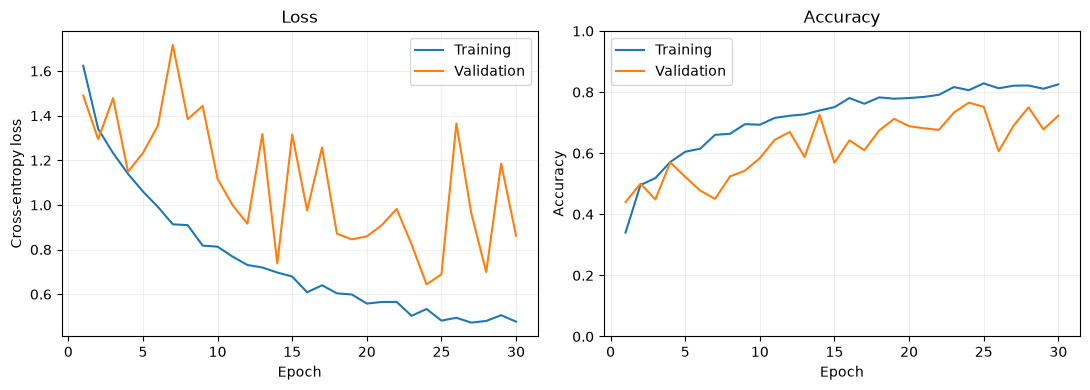

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv(OUT / "cnn_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.epoch, history.train_loss, label="Training")
axes[0].plot(history.epoch, history.validation_loss, label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
axes[1].plot(history.epoch, history.train_accuracy, label="Training")
axes[1].plot(history.epoch, history.validation_accuracy, label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "cnn_training_curves.png", dpi=170)
plt.show()

## Evaluate my selected checkpoint

Only after completing the planned epochs and freezing the checkpoint, I evaluated the fixed test set once. I did not change the CNN based on this test result. This is the same test split used in earlier experiments, so it is not a newly collected independent test set. Similar building scenes may remain across the splits.

The following recorded output comes from the actual evaluation run. The saved scores are also available in `results/cnn_metrics.json`.


In [4]:
from pathlib import Path
import csv, json, os, time
os.environ["MPLCONFIGDIR"] = str(Path("results/.mpl-cache"))
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from cnn_model import build_model, prepare_image
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path.cwd()
OUT = ROOT / "results"
DATASET = ROOT / "BD3_original_dataset"
if not DATASET.exists():
    DATASET = Path("/Users/daryn/Desktop/daat/BD3_original_dataset")
torch.set_num_threads(4)
with (OUT / "cnn_history.csv").open() as file:
    history = list(csv.DictReader(file))
assert len(history) == 30, "Wait for all 30 planned epochs before testing."
best = json.loads((OUT / "cnn_best_validation.json").read_text())
classes = best["classes"]
with (ROOT / "results/split_manifest.csv").open() as file:
    rows = sorted((row for row in csv.DictReader(file) if row["split"] == "test"), key=lambda row: row["path"])
images = []
for row in rows:
    with Image.open(DATASET / row["path"]) as image:
        images.append(prepare_image(image))
X = torch.stack(images)
y = np.array([classes.index(row["label"]) for row in rows])
model = build_model()
model.load_state_dict(torch.load(ROOT / "models/cnn.pt", map_location="cpu", weights_only=True))
model.eval()
start = time.perf_counter()
scores = []
with torch.inference_mode():
    for batch in X.split(64):
        scores.append(model(batch).softmax(1).numpy())
predict_seconds = time.perf_counter() - start
probabilities = np.concatenate(scores)
prediction = probabilities.argmax(1)
matrix = confusion_matrix(y, prediction, labels=range(7))
metrics = {"model": "CNN trained from scratch", "pretrained": False,
    "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
    "epochs_planned": 30, "best_epoch": best["epoch"], "classes": classes,
    "validation_accuracy": best["validation_accuracy"], "validation_macro_f1": best["validation_macro_f1"],
    "checkpoint_selection": "highest validation macro F1 across 30 planned epochs",
    "split_counts": {"train": 2725, "validation": 584, "test": len(rows)},
    "test_accuracy": accuracy_score(y, prediction), "test_precision_macro": precision_score(y, prediction, average="macro", zero_division=0),
    "test_recall_macro": recall_score(y, prediction, average="macro", zero_division=0),
    "test_macro_f1": f1_score(y, prediction, average="macro"), "test_balanced_accuracy": balanced_accuracy_score(y, prediction),
    "fit_seconds": sum(float(epoch["seconds"]) for epoch in history), "predict_seconds": predict_seconds,
    "timing_note": "Epoch time includes training and validation; prediction time excludes image loading/preprocessing.",
    "classification_report": classification_report(y, prediction, labels=range(7), target_names=classes, output_dict=True, zero_division=0),
    "confusion_matrix": matrix.tolist(), "correct_count": int((prediction == y).sum()),
    "training_settings": {"optimizer": "Adam", "learning_rate": 0.001, "loss": "CrossEntropyLoss", "batch_size": 32, "seed": 42,
                          "image_size": [96, 96], "augmentation": "training-only horizontal flip and random rotation ±10 degrees"},
    "test_reuse_note": "This fixed test split was previously evaluated for earlier models. It was not used to select CNN epochs or settings."}
(OUT / "cnn_metrics.json").write_text(json.dumps(metrics, indent=2))
np.save(OUT / "cnn_test_probabilities.npy", probabilities)
with (OUT / "cnn_test_predictions.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=["path", "true_label", "predicted_label"] + [f"prob_{label}" for label in classes])
    writer.writeheader()
    writer.writerows({"path": row["path"], "true_label": row["label"], "predicted_label": classes[pred],
                      **{f"prob_{label}": float(score) for label, score in zip(classes, scores)}}
                     for row, pred, scores in zip(rows, prediction, probabilities))
fig, ax = plt.subplots(figsize=(8, 6.5))
ConfusionMatrixDisplay(matrix, display_labels=[label.replace("_", " ") for label in classes]).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35)
ax.set_title("CNN trained from scratch — held-out test")
fig.tight_layout()
fig.savefig(OUT / "cnn_confusion_matrix.png", dpi=180, bbox_inches="tight")
print("FINAL CNN TEST", metrics["test_accuracy"], "macro F1", metrics["test_macro_f1"], "correct", metrics["correct_count"], "/", len(rows))
print("Best checkpoint epoch", best["epoch"], "validation accuracy", best["validation_accuracy"])
print(classification_report(y, prediction, target_names=classes, digits=4))


Matplotlib is building the font cache; this may take a moment.
FINAL CNN TEST 0.7791095890410958 macro F1 0.7741452258579556 correct 455 / 584
Best checkpoint epoch 24 validation accuracy 0.7654109589041096
              precision    recall  f1-score   support

       algae     0.9062    0.9457    0.9255        92
 major_crack     0.7887    0.6512    0.7134        86
 minor_crack     0.6341    0.5977    0.6154        87
     peeling     0.8281    0.6795    0.7465        78
       plain     0.8878    0.9775    0.9305        89
    spalling     0.8205    0.8533    0.8366        75
       stain     0.5895    0.7273    0.6512        77

    accuracy                         0.7791       584
   macro avg     0.7793    0.7760    0.7741       584
weighted avg     0.7824    0.7791    0.7773       584



## My result

My randomly initialized CNN correctly classified **455 of 584 test images (77.91%)**, with macro F1 **0.7741**. I selected epoch **24** using validation macro F1. This CNN is a separate extension to the required cross-validated classical models. The validation checkpoint selection is not five-fold cross-validation. I use no pretrained weights.

The model can confuse similar surface conditions, particularly the two crack classes. Every uploaded image receives one of the seven labels, including unfamiliar or unrelated images.

## Update my website

I save my best CNN weights as `models/cnn.pt`. After training and evaluation, this cell updates the CNN entry in the website and its comparison table while keeping the classical model results. The report remains a snapshot of the recorded run.

In [5]:
cnn_name = "CNN trained from scratch"
metrics = json.loads((OUT / "cnn_metrics.json").read_text())
registry_path = ROOT / "models/registry.json"
registry = json.loads(registry_path.read_text()) if registry_path.exists() else {}
registry[cnn_name] = {"type": "cnn", "file": "models/cnn.pt",
                      "test_accuracy": metrics["test_accuracy"], "classes": metrics["classes"]}
registry_path.write_text(json.dumps(registry, indent=2))

cnn_row = {"Model": cnn_name, "Accuracy": metrics["test_accuracy"],
           "Precision macro": metrics["test_precision_macro"], "Recall macro": metrics["test_recall_macro"],
           "F1 macro": metrics["test_macro_f1"], "Balanced accuracy": metrics["test_balanced_accuracy"],
           "Development accuracy": np.nan, "Fit seconds": metrics["fit_seconds"],
           "Predict seconds": metrics["predict_seconds"]}
comparison_path = OUT / "model_comparison.csv"
comparison = pd.read_csv(comparison_path) if comparison_path.exists() else pd.DataFrame(columns=cnn_row)
comparison = comparison[comparison.Model != cnn_name]
comparison = pd.concat([comparison, pd.DataFrame([cnn_row])], ignore_index=True)
comparison.to_csv(comparison_path, index=False)
print("Updated the CNN website entry and comparison row.")

Updated the CNN website entry and comparison row.
